In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

import optuna

In [2]:
data_path = '../src/clean_data.csv'

In [3]:
df = pd.read_csv(data_path, index_col=0)
df.head()

,record_id,r_peak,annotation_sample,type,dist_from_annotation,x_0,x_1,x_2,x_3,x_4,...,x_171,x_172,x_173,x_174,x_175,x_176,x_177,x_178,x_179,anomaly
0,100,370,370.0,N,0.0,-0.280,-0.295,-0.305,-0.315,-0.305,...,-0.455,-0.450,-0.435,-0.445,-0.450,-0.455,-0.470,-0.460,-0.455,0
1,100,663,662.0,N,1.0,-0.335,-0.330,-0.335,-0.345,-0.345,...,-0.435,-0.430,-0.435,-0.420,-0.420,-0.420,-0.420,-0.425,-0.425,0
2,100,947,946.0,N,1.0,-0.345,-0.345,-0.345,-0.340,-0.310,...,-0.375,-0.365,-0.370,-0.385,-0.395,-0.385,-0.385,-0.370,-0.365,0
3,100,1231,1231.0,N,0.0,-0.330,-0.320,-0.290,-0.290,-0.300,...,-0.470,-0.455,-0.460,-0.440,-0.435,-0.425,-0.430,-0.445,-0.450,0
4,100,1515,1515.0,N,0.0,-0.320,-0.310,-0.305,-0.305,-0.275,...,-0.445,-0.440,-0.435,-0.430,-0.430,-0.450,-0.445,-0.445,-0.435,0


In [5]:
id_columns = [
    'record_id',
    'r_peak',
    'annotation_sample',
    'type',
    'dist_from_annotation',
    'anomaly'
]

feature_columns = [
    col for col in df.columns
    if col not in id_columns
]

In [6]:
print(feature_columns)

['x_0', 'x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7', 'x_8', 'x_9', 'x_10', 'x_11', 'x_12', 'x_13', 'x_14', 'x_15', 'x_16', 'x_17', 'x_18', 'x_19', 'x_20', 'x_21', 'x_22', 'x_23', 'x_24', 'x_25', 'x_26', 'x_27', 'x_28', 'x_29', 'x_30', 'x_31', 'x_32', 'x_33', 'x_34', 'x_35', 'x_36', 'x_37', 'x_38', 'x_39', 'x_40', 'x_41', 'x_42', 'x_43', 'x_44', 'x_45', 'x_46', 'x_47', 'x_48', 'x_49', 'x_50', 'x_51', 'x_52', 'x_53', 'x_54', 'x_55', 'x_56', 'x_57', 'x_58', 'x_59', 'x_60', 'x_61', 'x_62', 'x_63', 'x_64', 'x_65', 'x_66', 'x_67', 'x_68', 'x_69', 'x_70', 'x_71', 'x_72', 'x_73', 'x_74', 'x_75', 'x_76', 'x_77', 'x_78', 'x_79', 'x_80', 'x_81', 'x_82', 'x_83', 'x_84', 'x_85', 'x_86', 'x_87', 'x_88', 'x_89', 'x_90', 'x_91', 'x_92', 'x_93', 'x_94', 'x_95', 'x_96', 'x_97', 'x_98', 'x_99', 'x_100', 'x_101', 'x_102', 'x_103', 'x_104', 'x_105', 'x_106', 'x_107', 'x_108', 'x_109', 'x_110', 'x_111', 'x_112', 'x_113', 'x_114', 'x_115', 'x_116', 'x_117', 'x_118', 'x_119', 'x_120', 'x_121', 'x_122', 'x

In [7]:
record_ids = df['record_id'].unique()

train_ids, temp_ids = train_test_split(
    record_ids,
    test_size=0.4,
    random_state=42
)

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.5,
    random_state=42
)

print("Train:", len(train_ids))
print("Validation:", len(val_ids))
print("Test:", len(test_ids))

Train: 27
Validation: 9
Test: 10


In [8]:
train_df_all = df[
    df['record_id'].isin(train_ids)
].copy()

train_df = train_df_all[
    train_df_all['anomaly'] == 0
].copy()

val_df = df[
    df['record_id'].isin(val_ids)
].copy()

test_df = df[
    df['record_id'].isin(test_ids)
].copy()

In [9]:
train_df['anomaly'].value_counts()

anomaly
0    44564
Name: count, dtype: int64

In [10]:
val_df['anomaly'].value_counts()

anomaly
0    13753
1     2916
Name: count, dtype: int64

In [11]:
test_df['anomaly'].value_counts()

anomaly
0    14991
1     7040
Name: count, dtype: int64

In [12]:
X_train = train_df[feature_columns]

X_val = val_df[feature_columns]
y_val = val_df['anomaly']

X_test = test_df[feature_columns]
y_test = test_df['anomaly']

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [14]:
pca = PCA(n_components=0.95)

In [15]:
X_train_pca = pca.fit_transform(X_train_scaled)

X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [16]:
print("Przed PCA:", X_train_scaled.shape)
print("Po PCA:", X_train_pca.shape)

Przed PCA: (44564, 180)
Po PCA: (44564, 5)


In [17]:
def objective(trial):
    nu = trial.suggest_float('nu', 0.001, 0.2, log=True)
    gamma = trial.suggest_float('gamma', 1e-4, 1.0, log=True)
    kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])
    tol = trial.suggest_float('tol', 1e-5, 1e-2, log=True)
    
    params = {
        'kernel': kernel,
        'nu': nu,
        'gamma': gamma,
        'tol': tol
    }
    
    if kernel == 'poly':
        params['degree'] = trial.suggest_int('degree', 2, 5)
        params['coef0'] = trial.suggest_float('coef0', -1, 1)
    
    elif kernel == 'sigmoid':
        params['coef0'] = trial.suggest_float('coef0', -1, 1)
        
    model = OneClassSVM(**params)
    model.fit(X_train_pca)
    
    pred = model.predict(X_val_pca)
    y_pred = np.where(
        pred == -1,
        1,
        0
    )
    
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)
    
    trial.set_user_attr('precision', precision)
    trial.set_user_attr('recall', recall)
    
    return f1

In [18]:
study = optuna.create_study(
    direction='maximize'
)

[I 2026-09-09 11:36:39,671] A new study created in memory with name: no-name-ff10bf34-7a38-41bb-a4e8-e1570fe82016


In [19]:
study.optimize(
    objective,
    n_trials=30
)

[I 2026-09-09 11:36:57,049] Trial 0 finished with value: 0.02982233502538071 and parameters: {'nu': 0.1744220563019906, 'gamma': 0.003661125561025466, 'kernel': 'sigmoid', 'tol': 4.854758898256041e-05, 'coef0': 0.43724620150336535}. Best is trial 0 with value: 0.02982233502538071.
[I 2026-09-09 11:36:57,525] Trial 1 finished with value: 0.0 and parameters: {'nu': 0.008872446190344064, 'gamma': 0.04483139295567355, 'kernel': 'poly', 'tol': 0.0005108911178210563, 'degree': 4, 'coef0': -0.8519087707139279}. Best is trial 0 with value: 0.02982233502538071.
[I 2026-09-09 11:37:02,583] Trial 2 finished with value: 0.0135464643727987 and parameters: {'nu': 0.06922357842805339, 'gamma': 0.00038133305114649375, 'kernel': 'poly', 'tol': 0.0001583775030513617, 'degree': 2, 'coef0': 0.1761402689815783}. Best is trial 0 with value: 0.02982233502538071.
[I 2026-09-09 11:37:06,890] Trial 3 finished with value: 0.11005103172842245 and parameters: {'nu': 0.05077949576218094, 'gamma': 0.0001706782997976

In [20]:
best_trial = study.best_trial

print("F1:", best_trial.value)
print("Precision:", best_trial.user_attrs['precision'])
print("Recall:", best_trial.user_attrs['recall'])
print("Params:", best_trial.params)

F1: 0.5008029647930822
Precision: 0.3913882988994014
Recall: 0.6951303155006858
Params: {'nu': 0.04553089639984008, 'gamma': 0.0017183981606918534, 'kernel': 'rbf', 'tol': 4.1568033610980257e-05}


In [21]:
best_model = OneClassSVM(**best_trial.params)
best_model.fit(X_train_scaled)

,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.0017183981606918534
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",4.1568033610980257e-05
,"nu nu: float, default=0.5An upper bound on the fraction of trainingerrors and a lower bound of the fraction of supportvectors. Should be in the interval (0, 1]. By default 0.5will be taken.",0.04553089639984008
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1
Name,Type,Value


In [22]:
val_pred = best_model.predict(X_val_scaled)
y_val_pred = np.where(val_pred == -1, 1, 0)

cm = confusion_matrix(y_val, y_val_pred)

print(cm)

[[10651  3102]
 [  648  2268]]


In [23]:
val_results = val_df.copy()

val_results['prediction'] = y_val_pred

In [25]:
type_results = val_results.groupby('type').agg(
    count=('type', 'size'),
    detected=('prediction', 'sum')
)

type_results['predicted_anomaly_rate'] = (
    type_results['detected']
    / type_results['count']
)

type_results

,count,detected,predicted_anomaly_rate
type,,,
A,13,8,0.615385
E,101,88,0.871287
F,2,1,0.500000
L,2014,1622,0.805362
N,13753,3102,0.225551
R,85,0,0.000000
V,701,549,0.783167


In [26]:
pca_vis = PCA(n_components=2)

X_vis = pca_vis.fit_transform(
    X_val_scaled
)

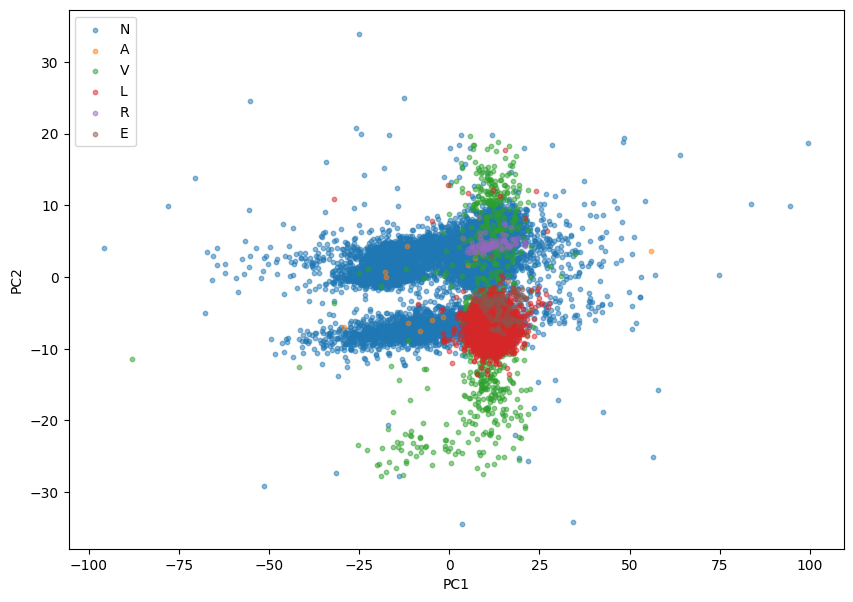

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for beat_type in ['N', 'A', 'V', 'L', 'R', 'E']:

    mask = val_df['type'].to_numpy() == beat_type

    plt.scatter(
        X_vis[mask, 0],
        X_vis[mask, 1],
        s=10,
        alpha=0.5,
        label=beat_type
    )

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

In [28]:
print(
    pca_vis.explained_variance_ratio_
)

print(
    pca_vis.explained_variance_ratio_.sum()
)

[0.73832203 0.11818809]
0.8565101236563816


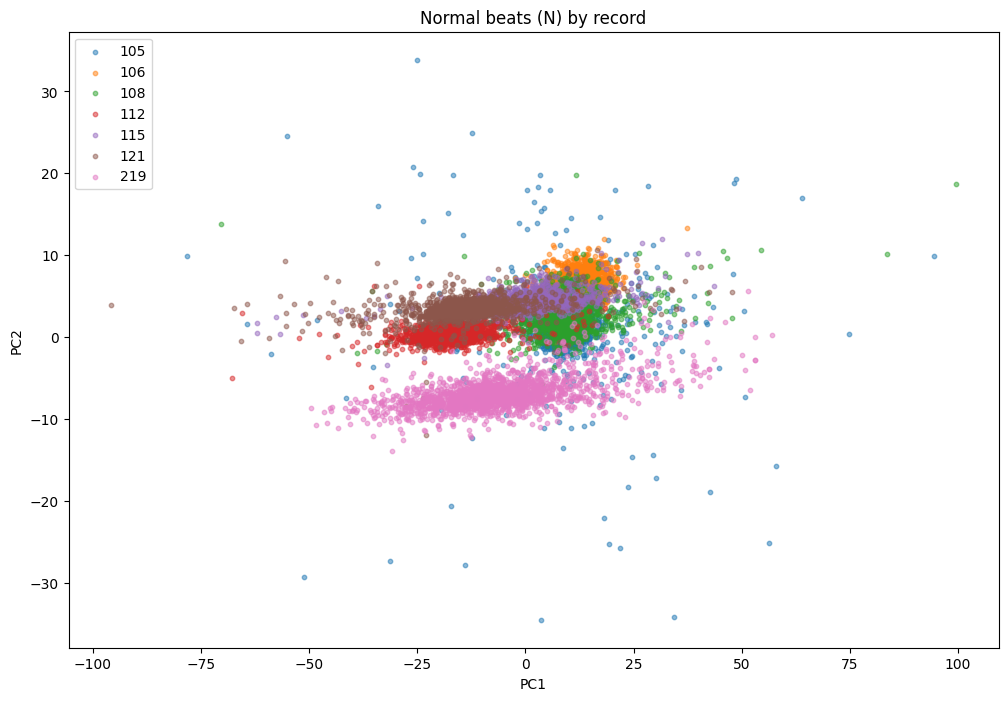

In [29]:
normal_mask = val_df['type'].to_numpy() == 'N'

normal_pca = X_vis[normal_mask]
normal_records = val_df.loc[
    val_df['type'] == 'N',
    'record_id'
].to_numpy()

plt.figure(figsize=(12, 8))

for record_id in np.unique(normal_records):

    mask = normal_records == record_id

    plt.scatter(
        normal_pca[mask, 0],
        normal_pca[mask, 1],
        s=10,
        alpha=0.5,
        label=str(record_id)
    )

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Normal beats (N) by record')
plt.legend()
plt.show()